In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

raw_df = pd.read_csv('clean_toy_sales.csv')
df = raw_df.copy()
df.isna().sum()

transaction_id         0
transaction_date       0
quarter                0
brand                  0
brand_type             0
product_category       0
product_subcategory    0
product_id             0
region                 0
city                   0
city_tier              0
sales_channel          0
channel_type           0
target_age_group       0
unit_price_inr         0
quantity               0
discount_percentage    0
customer_rating        0
safety_certified       0
returned               0
customer_type          0
year                   0
month                  0
month_name             0
day_of_week            0
net_revenue_inr        0
dtype: int64

In [4]:
df.dtypes

transaction_id                    str
transaction_date       datetime64[us]
quarter                           str
brand                             str
brand_type                        str
product_category                  str
product_subcategory               str
product_id                        str
region                            str
city                              str
city_tier                         str
sales_channel                     str
channel_type                      str
target_age_group                  str
unit_price_inr                float64
quantity                        int64
discount_percentage           float64
customer_rating               float64
safety_certified                  str
returned                          str
customer_type                     str
year                            int64
month                           int64
month_name                        str
day_of_week                       str
net_revenue_inr               float64
dtype: objec

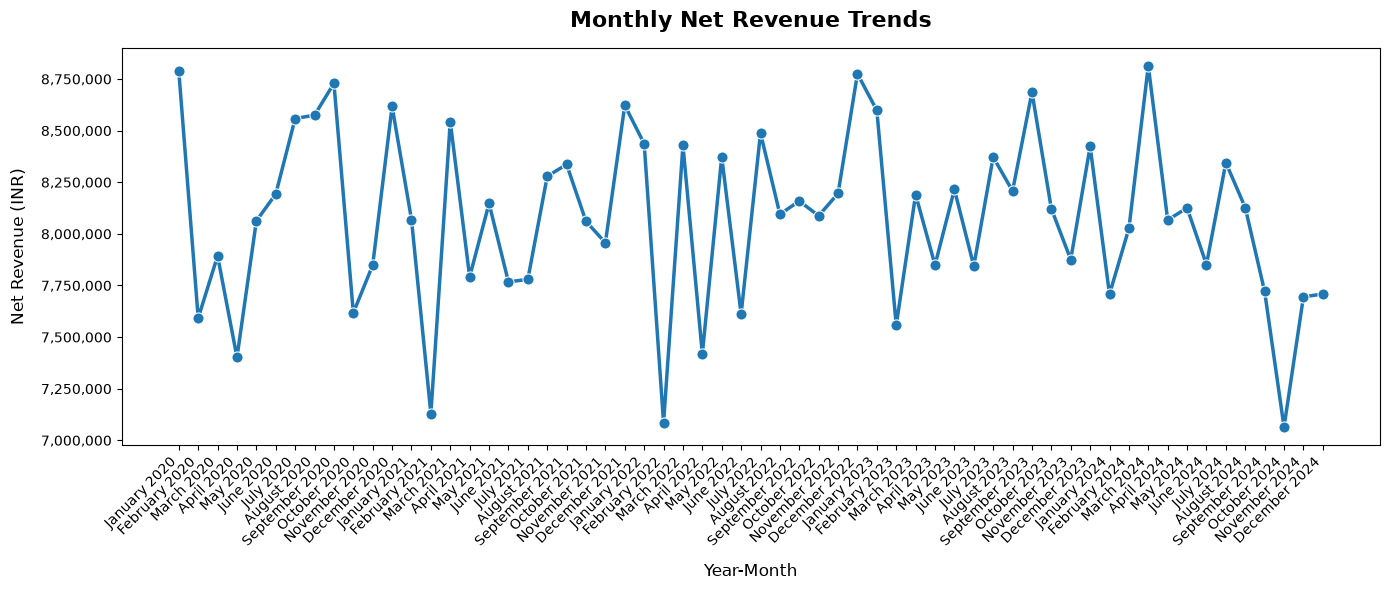

In [21]:
# 1	Create a line chart showing monthly net revenue trends across different years.

df['transaction_date'] = pd.to_datetime(df['transaction_date'], format='mixed', errors='coerce')

df['year_month'] = df['transaction_date'].dt.to_period('M')

revenue_trends = df.groupby(['year_month'])['net_revenue_inr'].sum().reset_index()

revenue_trends['year_month_str'] = revenue_trends['year_month'].dt.strftime('%B %Y')

plt.figure(figsize=(14, 6))

# 3. Plot with enhanced line, color, and marker styling
ax = sns.lineplot(
    data=revenue_trends,
    x='year_month_str',
    y='net_revenue_inr',
    marker='o',
    color='#1f77b4',  # Professional deep blue
    linewidth=2.5,
    markersize=8,
    sort=False,
)

# 4. Format y-axis values with commas for better readability
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 5. Clear titles and labels with padding
plt.title('Monthly Net Revenue Trends', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Year-Month', fontsize=12, labelpad=10)
plt.ylabel('Net Revenue (INR)', fontsize=12, labelpad=10)

# 6. Clean up tick marks and alignment
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

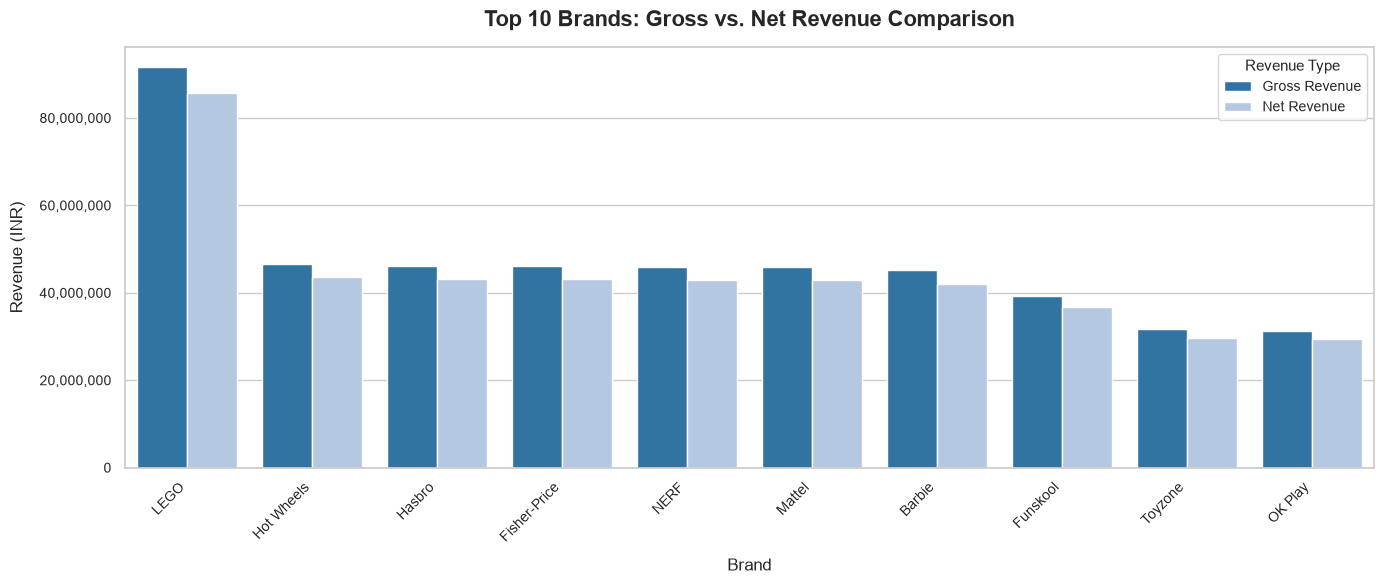

In [22]:
# 2	Create a grouped bar chart comparing gross revenue and net revenue across the top 10 brands.

df['gross_revenue_inr'] = df['quantity'] * df['unit_price_inr']

brand_revenue = (
    df.groupby('brand')[['gross_revenue_inr', 'net_revenue_inr']]
    .sum()
    .reset_index()
)

# 2. Find the top 10 brands based on total combined revenue
brand_revenue['total_revenue'] = (
    brand_revenue['gross_revenue_inr'] + brand_revenue['net_revenue_inr']
)
top_10_brands = (
    brand_revenue.sort_values(by='total_revenue', ascending=False)
    .head(10)
    .drop(columns='total_revenue')
)

# 3. Melt the dataframe to long format for Seaborn grouped bar plotting
top_10_melted = pd.melt(
    top_10_brands,
    id_vars=['brand'],
    value_vars=['gross_revenue_inr', 'net_revenue_inr'],
    var_name='revenue_type',
    value_name='amount_inr',
)

# Clean up the revenue type names for clear legend labels
top_10_melted['revenue_type'] = top_10_melted['revenue_type'].replace(
    {
        'gross_revenue_inr': 'Gross Revenue',
        'net_revenue_inr': 'Net Revenue',
    }
)

# 4. Set theme and plot the grouped bar chart
sns.set_theme(style='whitegrid')
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=top_10_melted,
    x='brand',
    y='amount_inr',
    hue='revenue_type',
    palette=['#1f77b4', '#aec7e8'],  # Distinct primary and light blue shades
)

# 5. Format y-axis numbers with commas for readability
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 6. Titles, labels, and layout cleanup
plt.title(
    'Top 10 Brands: Gross vs. Net Revenue Comparison',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Brand', fontsize=12, labelpad=10)
plt.ylabel('Revenue (INR)', fontsize=12, labelpad=10)
plt.legend(title='Revenue Type', fontsize=10, title_fontsize=11)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

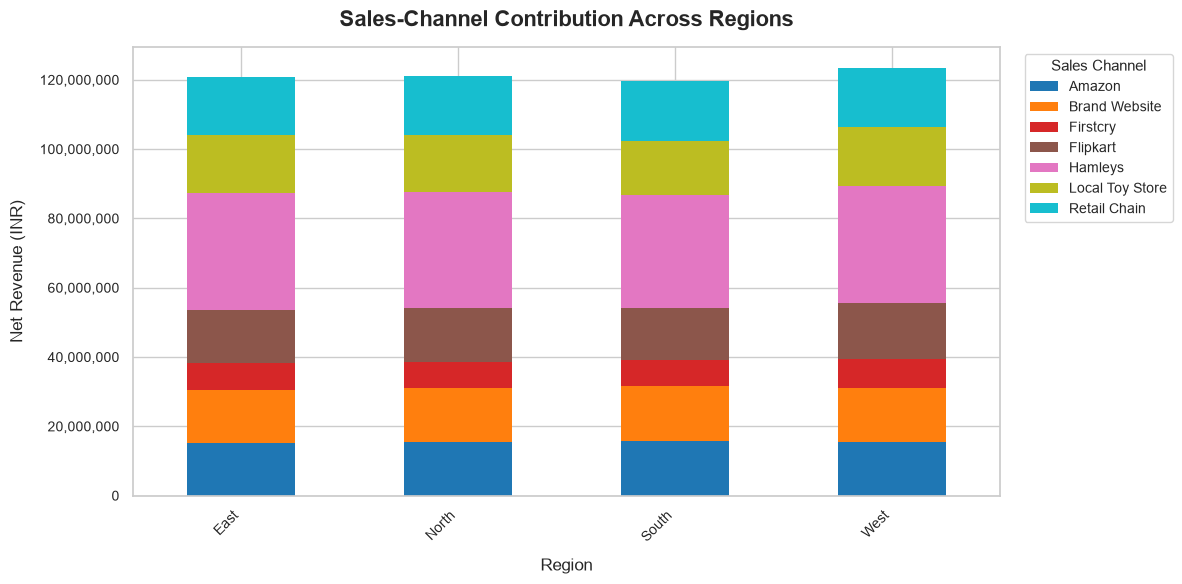

In [23]:
# 3	Create a stacked bar chart showing sales-channel contribution across different regions.

region_channel = df.pivot_table(
    index='region',
    columns='sales_channel',
    values='net_revenue_inr',
    aggfunc='sum',
).fillna(0)

# 2. Set theme and plot a stacked bar chart directly from the pivot table
sns.set_theme(style='whitegrid')
ax = region_channel.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='tab10',  # Clean, distinct color palette for channels
    edgecolor='none',
)

# 3. Format y-axis values with commas for better readability
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 4. Titles and labels with padding
plt.title(
    'Sales-Channel Contribution Across Regions',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Region', fontsize=12, labelpad=10)
plt.ylabel('Net Revenue (INR)', fontsize=12, labelpad=10)

# 5. Position legend neatly outside the plot area so it doesn't overlap bars
plt.legend(
    title='Sales Channel',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=10,
    title_fontsize=11,
)

# 6. Clean up tick alignment
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


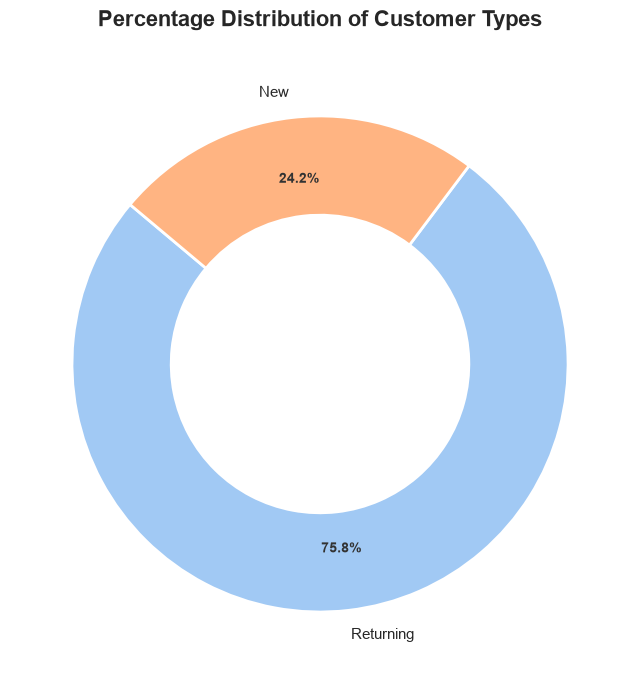

In [24]:
# 4	Create a pie/donut chart showing the percentage distribution of customer types.

customer_counts = df['customer_type'].value_counts()

# 2. Set up figure and color palette
plt.figure(figsize=(9, 7))
colors = sns.color_palette('pastel', len(customer_counts))

# 3. Create the donut chart using plt.pie with a center circle (wedgeprops width < 1)
wedges, texts, autotexts = plt.pie(
    customer_counts,
    labels=customer_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    pctdistance=0.75,
)

# 4. Style the text for high readability
plt.setp(autotexts, size=10, weight='bold', color='#333333')
plt.setp(texts, size=11, weight='medium')

# 5. Title and layout cleanup
plt.title(
    'Percentage Distribution of Customer Types',
    fontsize=16,
    fontweight='bold',
    pad=20,
)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_24744\2675143469.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


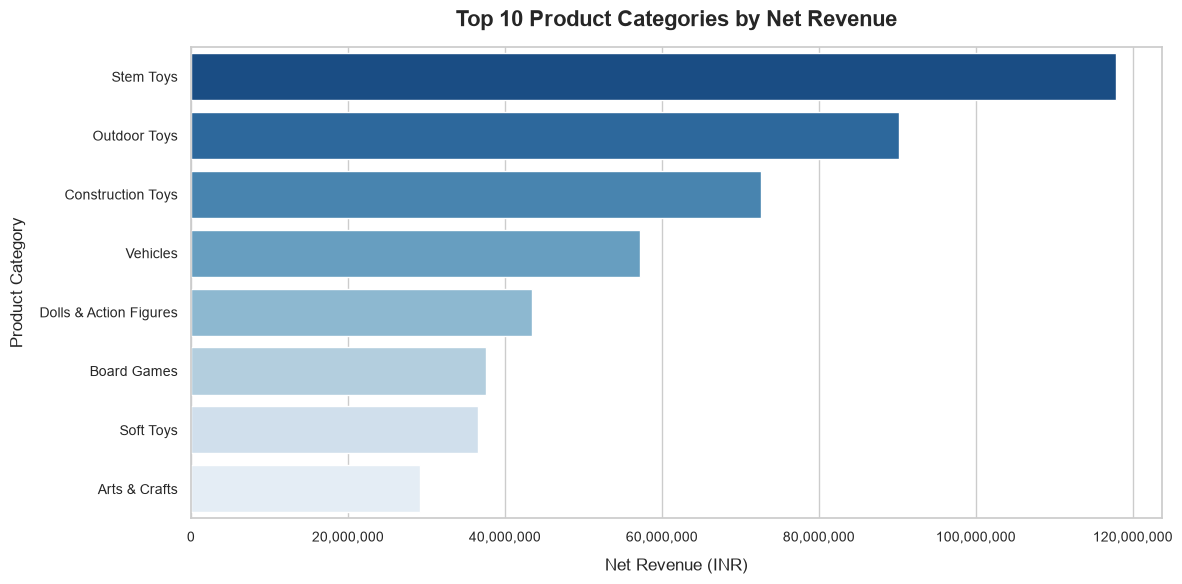

In [25]:
# 5	Create a horizontal bar chart showing the top 10 product categories by net revenue.

# 1. Aggregate net revenue by product category
category_revenue = (
    df.groupby('product_category')['net_revenue_inr'].sum().reset_index()
)

# 2. Get the top 10 product categories by net revenue
top_10_categories = category_revenue.sort_values(
    by='net_revenue_inr', ascending=False
).head(10)

# 3. Set theme and plot the horizontal bar chart
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_categories,
    x='net_revenue_inr',
    y='product_category',
    palette='Blues_r',  # Gradient palette: darker shades for higher revenue
    orient='h',
)

# 4. Format x-axis values with commas for readability
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 5. Titles, labels, and layout adjustments
plt.title(
    'Top 10 Product Categories by Net Revenue',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Net Revenue (INR)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12, labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

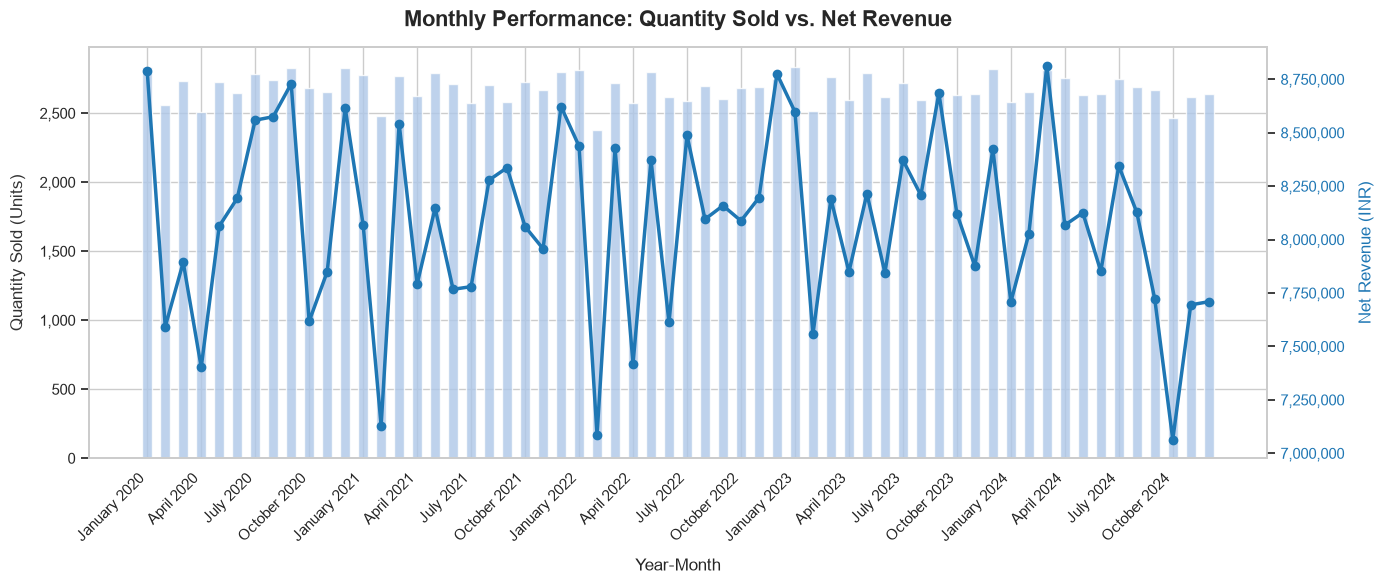

In [27]:
# 6	Create a dual-axis chart comparing monthly quantity sold and net revenue.

df['transaction_date'] = pd.to_datetime(
    df['transaction_date'], format='mixed', errors='coerce'
)
df['year_month'] = df['transaction_date'].dt.to_period('M')

monthly_metrics = (
    df.groupby('year_month')[['quantity', 'net_revenue_inr']]
    .sum()
    .reset_index()
)
monthly_metrics = monthly_metrics.sort_values('year_month')
monthly_metrics['year_month_str'] = monthly_metrics['year_month'].dt.strftime(
    '%B %Y'
)

# 2. Set theme and create figure with a primary axis (ax1)
sns.set_theme(style='whitegrid')
fig, ax1 = plt.subplots(figsize=(14, 6))

x_indexes = range(len(monthly_metrics))

# 3. Plot Quantity Sold as bars on ax1
ax1.bar(
    x_indexes,
    monthly_metrics['quantity'],
    color='#aec7e8',
    alpha=0.8,
    width=0.55,
    label='Quantity Sold',
)
ax1.set_xlabel('Year-Month', fontsize=12, labelpad=10)
ax1.set_ylabel(
    'Quantity Sold (Units)', color='#333333', fontsize=12, labelpad=10
)
ax1.tick_params(axis='y')
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 4. Create secondary axis (ax2) and plot Net Revenue line
ax2 = ax1.twinx()
ax2.plot(
    x_indexes,
    monthly_metrics['net_revenue_inr'],
    color='#1f77b4',
    marker='o',
    linewidth=2.5,
    markersize=6,
    label='Net Revenue (INR)',
)
ax2.set_ylabel(
    'Net Revenue (INR)', color='#1f77b4', fontsize=12, labelpad=10
)
ax2.tick_params(axis='y', labelcolor='#1f77b4')
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax2.grid(False)

# 5. FIX: Show only every 3rd month label to prevent overcrowding
step = 3  # Change to 6 if you want even more space
ax1.set_xticks(x_indexes[::step])
ax1.set_xticklabels(
    monthly_metrics['year_month_str'][::step], rotation=45, ha='right'
)

# 6. Title and layout adjustments
plt.title(
    'Monthly Performance: Quantity Sold vs. Net Revenue',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.show()

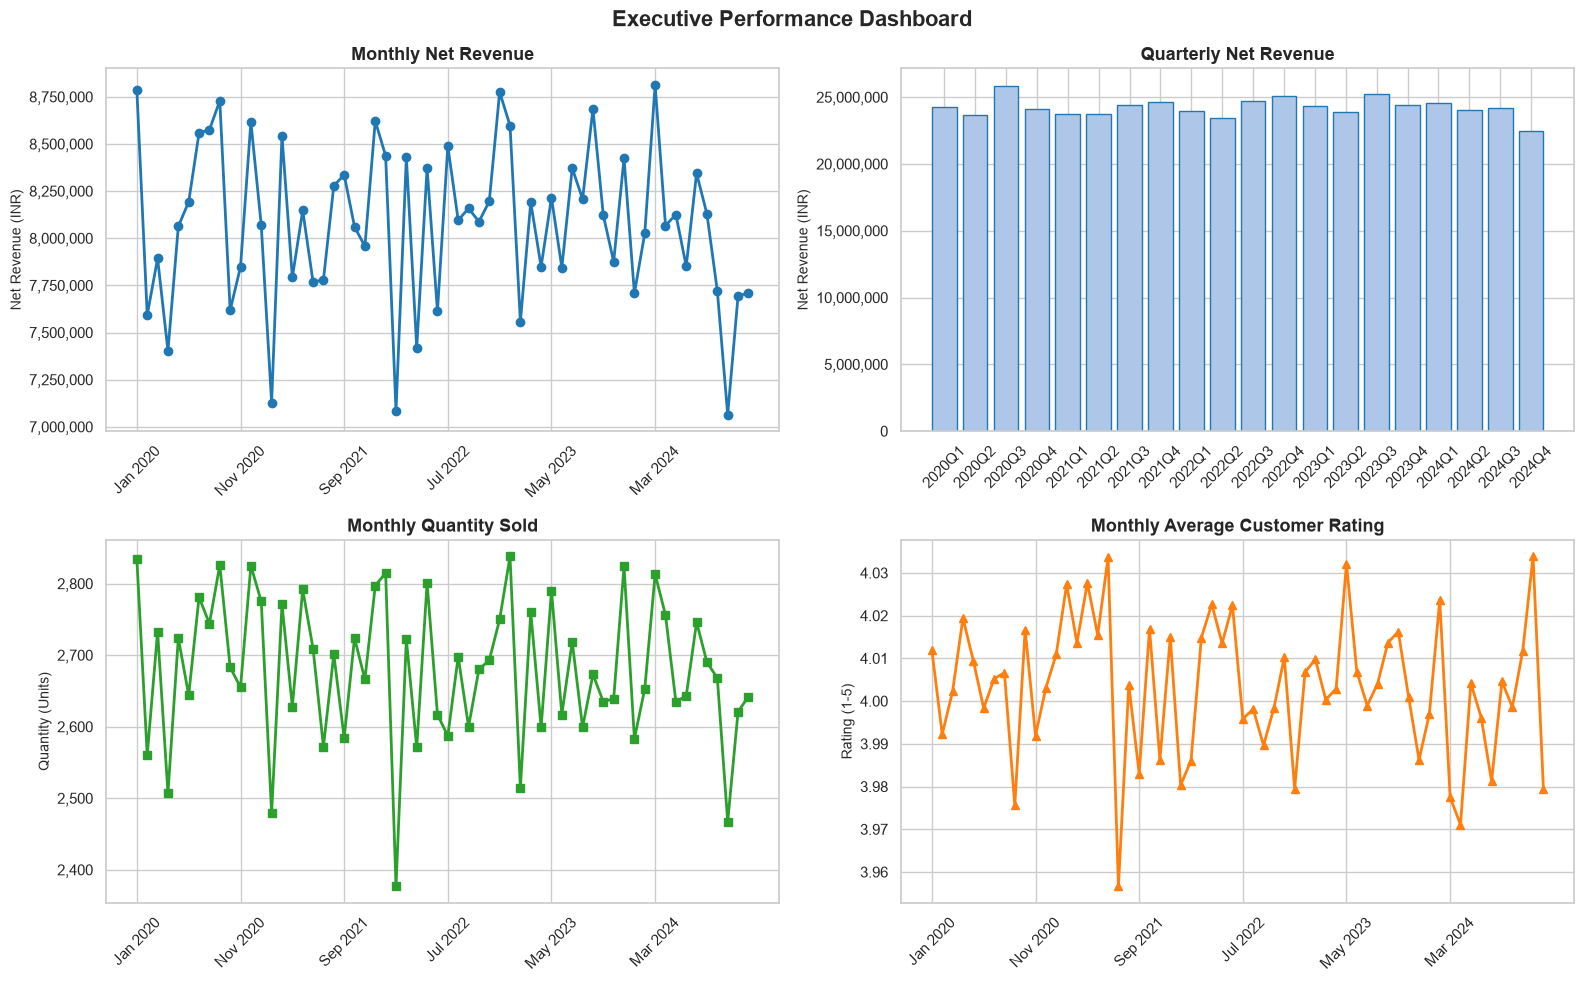

In [28]:
# 7	Create a subplot containing four charts: monthly revenue, quarterly revenue, quantity sold, and average customer rating.

# 1. Parse dates and create time-period columns
df['transaction_date'] = pd.to_datetime(
    df['transaction_date'], format='mixed', errors='coerce'
)
df['year_month'] = df['transaction_date'].dt.to_period('M')
df['year_quarter'] = df['transaction_date'].dt.to_period('Q')

# 2. Aggregate Data
# Monthly Revenue
monthly_rev = (
    df.groupby('year_month')['net_revenue_inr'].sum().reset_index()
)
monthly_rev['month_str'] = monthly_rev['year_month'].dt.strftime('%b %Y')

# Quarterly Revenue
quarterly_rev = (
    df.groupby('year_quarter')['net_revenue_inr'].sum().reset_index()
)
quarterly_rev['quarter_str'] = quarterly_rev['year_quarter'].astype(str)

# Monthly Quantity Sold
monthly_qty = df.groupby('year_month')['quantity'].sum().reset_index()
monthly_qty['month_str'] = monthly_qty['year_month'].dt.strftime('%b %Y')

# Monthly Average Customer Rating (Assuming column is named 'customer_rating' or 'rating')
monthly_rating = (
    df.groupby('year_month')['customer_rating'].mean().reset_index()
)
monthly_rating['month_str'] = monthly_rating['year_month'].dt.strftime('%b %Y')

# 3. Set up the 2x2 Subplot Canvas
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# --- Subplot 1: Monthly Net Revenue ---
axes[0, 0].plot(
    monthly_rev['month_str'],
    monthly_rev['net_revenue_inr'],
    marker='o',
    color='#1f77b4',
    linewidth=2,
)
axes[0, 0].set_title('Monthly Net Revenue', fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel('Net Revenue (INR)', fontsize=10)
axes[0, 0].yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
axes[0, 0].tick_params(axis='x', rotation=45)
# Show every 4th label to avoid overcrowding
axes[0, 0].set_xticks(range(0, len(monthly_rev), max(1, len(monthly_rev) // 6)))

# --- Subplot 2: Quarterly Net Revenue ---
axes[0, 1].bar(
    quarterly_rev['quarter_str'],
    quarterly_rev['net_revenue_inr'],
    color='#aec7e8',
    edgecolor='#1f77b4',
)
axes[0, 1].set_title('Quarterly Net Revenue', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Net Revenue (INR)', fontsize=10)
axes[0, 1].yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
axes[0, 1].tick_params(axis='x', rotation=45)

# --- Subplot 3: Monthly Quantity Sold ---
axes[1, 0].plot(
    monthly_qty['month_str'],
    monthly_qty['quantity'],
    marker='s',
    color='#2ca02c',
    linewidth=2,
)
axes[1, 0].set_title('Monthly Quantity Sold', fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel('Quantity (Units)', fontsize=10)
axes[1, 0].yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_xticks(range(0, len(monthly_qty), max(1, len(monthly_qty) // 6)))

# --- Subplot 4: Average Customer Rating ---
axes[1, 1].plot(
    monthly_rating['month_str'],
    monthly_rating['customer_rating'],
    marker='^',
    color='#ff7f0e',
    linewidth=2,
)
axes[1, 1].set_title(
    'Monthly Average Customer Rating', fontsize=13, fontweight='bold'
)
axes[1, 1].set_ylabel('Rating (1-5)', fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].set_xticks(
    range(0, len(monthly_rating), max(1, len(monthly_rating) // 6))
)

# Overall layout cleanup
plt.suptitle(
    'Executive Performance Dashboard', fontsize=16, fontweight='bold', y=0.98
)
plt.tight_layout()
plt.show()

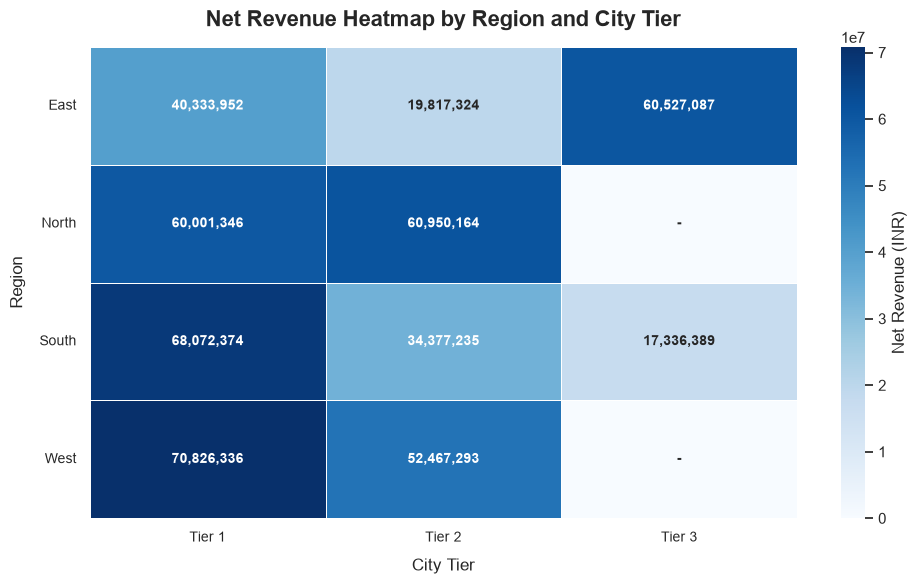

In [32]:
# 9	Create an annotated heatmap-style chart showing revenue generated by region and city tier.

# 1. Create a pivot table: Region as rows, City Tier as columns, summed Net Revenue as values
heatmap_data = df.pivot_table(
    index='region',
    columns='city_tier',
    values='net_revenue_inr',
    aggfunc='sum',
).fillna(0)

# 2. Create a custom formatted string matrix for clean currency annotations inside the cells
annot_data = heatmap_data.map(
    lambda x: f'{x:,.0f}' if x > 0 else '-'
)  # Use applymap if using older pandas versions

# 3. Set up the figure and plot the heatmap
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

ax = sns.heatmap(
    heatmap_data,
    annot=annot_data,
    fmt='',  # Pass empty string since annot is already a custom string matrix
    cmap='Blues',  # Professional blue gradient color map
    cbar_kws={
        'label': 'Net Revenue (INR)'
    },  # Color bar label for scale reference
    linewidths=0.5,  # Subtle grid lines separating cells
    linecolor='white',
    annot_kws={'size': 10, 'weight': 'bold'},
)

# 4. Titles, labels, and tick adjustments
plt.title(
    'Net Revenue Heatmap by Region and City Tier',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('City Tier', fontsize=12, labelpad=10)
plt.ylabel('Region', fontsize=12, labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)  # Keep region labels horizontal for clarity

plt.tight_layout()
plt.show()

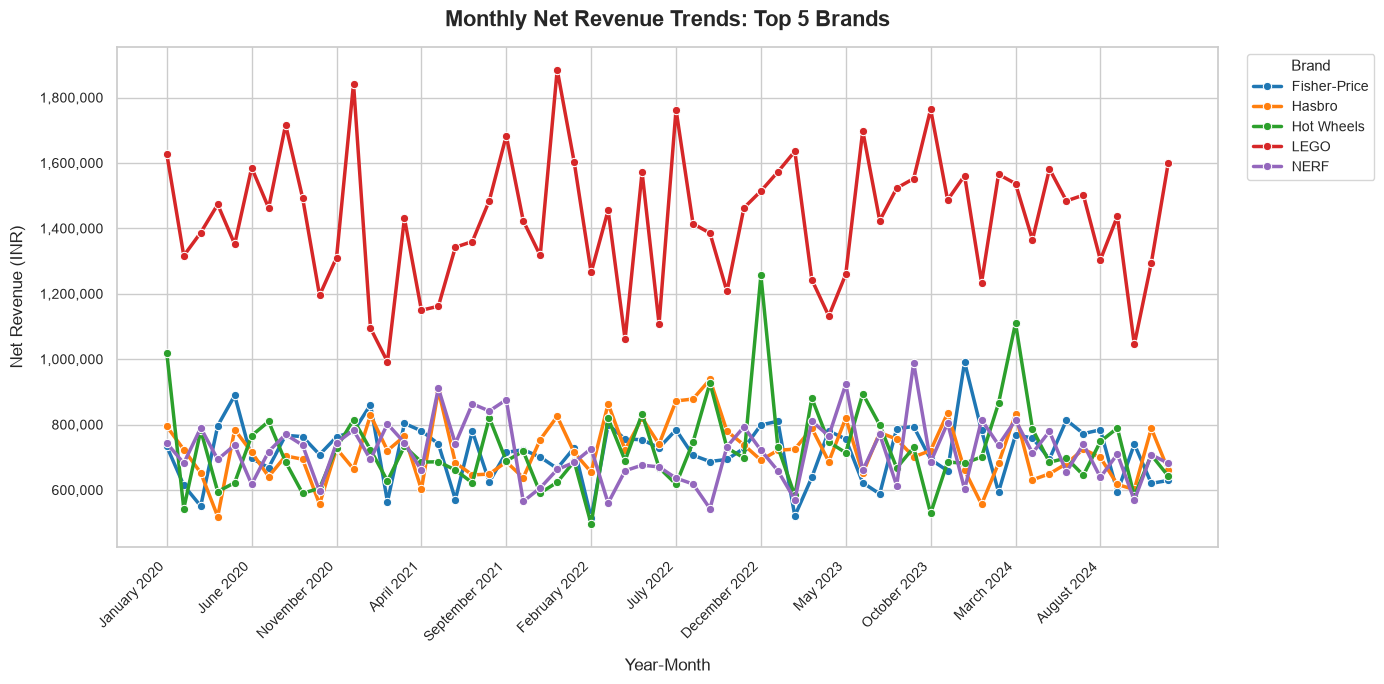

In [33]:
# 10	Create a multi-line chart comparing revenue trends across the top 5 brands over time.

# 1. Parse dates and create the year-month period
df['transaction_date'] = pd.to_datetime(
    df['transaction_date'], format='mixed', errors='coerce'
)
df['year_month'] = df['transaction_date'].dt.to_period('M')

# 2. Identify the top 5 brands by overall net revenue
top_5_brands_list = (
    df.groupby('brand')['net_revenue_inr']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

# 3. Filter the dataframe to keep only the top 5 brands
df_top_5 = df[df['brand'].isin(top_5_brands_list)]

# 4. Group by year-month and brand to get monthly revenue trends
brand_monthly_trends = (
    df_top_5.groupby(['year_month', 'brand'])['net_revenue_inr']
    .sum()
    .reset_index()
)

# Sort chronologically and create a readable string format for the x-axis
brand_monthly_trends = brand_monthly_trends.sort_values('year_month')
brand_monthly_trends['year_month_str'] = (
    brand_monthly_trends['year_month'].dt.strftime('%B %Y')
)

# 5. Set up the theme and multi-line chart
sns.set_theme(style='whitegrid')
plt.figure(figsize=(14, 7))

ax = sns.lineplot(
    data=brand_monthly_trends,
    x='year_month_str',
    y='net_revenue_inr',
    hue='brand',  # Creates a distinct line for each brand
    marker='o',
    linewidth=2.5,
    markersize=6,
    palette='tab10',  # Distinct color palette for each brand line
    sort=False,
)

# 6. Format y-axis values with commas for readability
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# 7. Titles, labels, and legend cleanup
plt.title(
    'Monthly Net Revenue Trends: Top 5 Brands',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Year-Month', fontsize=12, labelpad=10)
plt.ylabel('Net Revenue (INR)', fontsize=12, labelpad=10)

# Position legend neatly outside or on the side of the chart area
plt.legend(
    title='Brand',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=10,
    title_fontsize=11,
)

# Dynamic tick spacing to prevent text overcrowding on the x-axis
unique_months = brand_monthly_trends['year_month_str'].unique()
step = max(1, len(unique_months) // 12)
plt.xticks(
    range(0, len(unique_months), step),
    unique_months[::step],
    rotation=45,
    ha='right',
    fontsize=10,
)

plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

1	Create a line chart showing monthly net revenue trends across different years.
2	Create a grouped bar chart comparing gross revenue and net revenue across the top 10 brands.
3	Create a stacked bar chart showing sales-channel contribution across different regions.
4	Create a pie/donut chart showing the percentage distribution of customer types.
5	Create a horizontal bar chart showing the top 10 product categories by net revenue.
6	Create a dual-axis chart comparing monthly quantity sold and net revenue.
7	Create a subplot containing four charts: monthly revenue, quarterly revenue, quantity sold, and average customer rating.
8	Create an annotated heatmap-style chart showing revenue generated by region and city tier.
9	Create a multi-line chart comparing revenue trends across the top 5 brands over time.